# 10 · Probe the Model

Has the model learned which itemsets are frequent? A frequent itemset is a statement about *all* baskets, so we
turn the question around: let the model write N baskets of its own from just "Basket:", mine them with section 6's
exact miner, and compare with the truth — against a **ceiling**: what N *real* baskets recover at the same size.

**CPU notes.** Sampling uses my PyTorch port of the reference sampler (`work/mybasket/probe.py`), run as a background
job and saved to `work/checkpoints/`.

**Reductions vs the course (to save time) — read before comparing numbers:**
- **Model:** my 100-step checkpoint from section 9 (course: 800 steps), so it has seen an eighth of the baskets.
- **Sample size: 200 baskets** (course: 10,000). Writing baskets on this CPU took ~4–5 minutes per 100 (longer while
  another notebook ran), so the sampler was stopped after its second batch and only those 200 are kept. The ceiling is
  built from **200 real baskets**, so the comparison stays like-for-like.
- **Support floor raised from 0.2% to 5%.** In 200 baskets an itemset at 0.2% would be seen less than once; at 5% it
  is expected ~10 times. At this floor the truth is only **84 itemsets — the eight 5% planted sets and their parts**,
  all with support between 5% and 6%. So the band table is a single band (5%+, course: four bands from 0.2%), and
  everything rarer — all chance itemsets, all extensions, and the planted sets at 1%, 0.2% and 0.05% — is out of
  reach. This section can now only ask: *did the model learn the most common planted patterns?*
- The label table uses that one band (course: split at 1%), and the size table uses the same 5% cut (course: 0.5%).

**These results are very noisy because of the small sizes.** An itemset expected 10 times in 200 baskets can easily
show up 5 or 15 times, so even the ceiling (real baskets) misses some itemsets that sit right at 5%, and every recall
here is a rough estimate. Compare the model with its ceiling, not with the course's numbers.

In [1]:
import json
import os
import warnings
from pathlib import Path

os.environ["TRANSFORMERS_VERBOSITY"] = "error"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from thilimarketbasket.dataset import generate_dataset, classify_itemset
from thilimarketbasket.probe import recover_itemsets, recovery_by_support, precision_of, support_error

data = generate_dataset(n_baskets=100_000, seed=0)
names = [item.name for item in data.catalog]

FLOOR = 0.05                                    # 5% of baskets (course: 0.2% with 10,000 samples; see the note above)
truth = {i: s for i, s in data.truth.items() if len(i) > 1 and s >= FLOOR}
print(f"the truth we score against: {len(truth):,} itemsets of 2 to 5 items with support of at least {FLOOR:.1%}")
print(f"(at the course's 0.2% floor it would be {sum(len(i) > 1 and s >= 0.002 for i, s in data.truth.items()):,})")

STEPS, BATCH = 100, 16                          # my section 9 run (course: 800 x 16)
CHECKPOINT = Path("checkpoints") / f"baskets-{STEPS}x{BATCH}"

# The model's baskets, written by the background job (stopped early; see the note above)
SAMPLES = CHECKPOINT / "samples-kept.json"
sampled = json.loads(SAMPLES.read_text())
stats = json.loads((CHECKPOINT / "samples-kept-stats.json").read_text())
N = len(sampled)                                # baskets the model wrote = real baskets for the ceiling (course: 10,000)
print(f"N = {N:,} baskets (written in {stats['minutes']:.0f} minutes on this CPU)")

the truth we score against: 84 itemsets of 2 to 5 items with support of at least 5.0%
(at the course's 0.2% floor it would be 7,579)
N = 200 baskets (written in 8 minutes on this CPU)


## The ceiling: N real baskets

An itemset at the floor shows up only ~5% × 200 = 10 times in a sample, so even perfect baskets miss some by luck. Mine
N random real baskets the same way: that's what a perfect model would score.

In [2]:
rng = np.random.default_rng(2026)
real_sample = [data.baskets[i] for i in rng.choice(len(data.baskets), N, replace=False)]
ceiling = {i: s for i, s in recover_itemsets(real_sample, FLOOR).items() if len(i) > 1}

BANDS = [0.05, 1.01]                            # one band (see the note at the top); course: [0.002, 0.005, 0.01, 0.02, 1.01]; first edge = the floor
def my_recovery(found, truth, bands):
    """For each band of true support: how many true itemsets are in `found`?"""
    rows = []
    for low, high in zip(bands[:-1], bands[1:]):
        wanted = [i for i, s in truth.items() if low <= s < high]
        rows.append({"band": f"{low:.2%} to {min(high, 1):.2%}", "true itemsets": len(wanted),
                     "found": sum(i in found for i in wanted)})
    table = pd.DataFrame(rows)
    table["recall"] = table["found"] / table["true itemsets"]
    return table

mine = my_recovery(ceiling, truth, BANDS)
reference = pd.DataFrame(recovery_by_support(ceiling, truth, BANDS))
print("same numbers as the reference:", (mine["found"].values == reference["found"].values).all())
mine.round(3)

same numbers as the reference: True


,band,true itemsets,found,recall
0,5.00% to 100.00%,84,15,0.179


## Asking the model to write

From "Basket:", temperature 1.0 (the model's own distribution — no top-k), until end-of-text; names not in the
catalogue dropped, repeats kept once, a basket cut off at 240 tokens loses its last item. (Loaded at the top; the
sampler is `mybasket.probe.sample_baskets`, run as `python -m mybasket.jobs sample ...` and stopped early.)

In [3]:
print({k: round(v, 3) for k, v in stats.items() if k != "minutes"})

sizes = [len(b) for b in sampled]
print(f"{len(sampled):,} baskets, {np.mean(sizes):.1f} items each on average (real data: {np.mean([len(set(b)) for b in data.baskets]):.1f})")
print("an example:", sampled[0])

{'baskets': 200, 'items written': 1455, 'share not in catalogue': 0.227, 'share repeated': 0.012, 'baskets cut off': 0.005, 'mean items per basket': 5.535}
200 baskets, 5.5 items each on average (real data: 9.5)
an example: ['Masala Mantra Red Chilli Powder sachet 10 g', 'Kaapi Kingdom Soft Drink 2 L', 'Surya Grains Wheat Flour (Atta) 1 kg', 'Shubham Select Chana Dal 1 kg', 'Gokul Fresh Milk 500 ml', 'Cabbage 500 g', 'Onion 500 g', 'Rupa Rani Soap Bar 1 bar']


In [4]:
found = {i: s for i, s in recover_itemsets(sampled, FLOOR).items() if len(i) > 1}
print(f"the model's baskets contain {len(found):,} itemsets of 2 to 5 items at {FLOOR:.1%} or more")
print(f"real baskets, same sample size: {len(ceiling):,}   (the truth at this floor: {len(truth):,})")

table = my_recovery(found, truth, BANDS)
table["ceiling"] = mine["recall"]
table.round(3)

the model's baskets contain 0 itemsets of 2 to 5 items at 5.0% or more
real baskets, same sample size: 15   (the truth at this floor: 84)


,band,true itemsets,found,recall,ceiling
0,5.00% to 100.00%,84,0,0.0,0.179


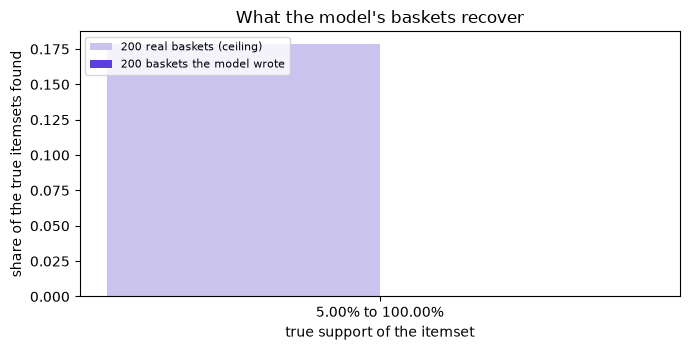

In [5]:
x = np.arange(len(table))
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(x - 0.2, table["ceiling"], 0.4, color="#c9c3ee", label=f"{N:,} real baskets (ceiling)")
ax.bar(x + 0.2, table["recall"], 0.4, color="#5b3de0", label=f"{N:,} baskets the model wrote")
ax.set_xticks(x, table["band"])
ax.set_xlabel("true support of the itemset")
ax.set_ylabel("share of the true itemsets found")
ax.legend(loc="upper left", fontsize=8)
ax.set_title("What the model's baskets recover")
plt.tight_layout()
plt.show()

## Which ones does it miss? By label, then by size

In [6]:
label_of = lambda itemset: classify_itemset(itemset, data.planted)
rows = []
for name, got in (("model", found), ("ceiling", ceiling)):
    for row in recovery_by_support(got, truth, [FLOOR, 1.01], group=label_of):
        rows.append({"who": name, "support": row["band"], "label": row["label"], "true": row["true"], "recall": row["recall"]})
by_label = pd.DataFrame(rows).pivot(index=["support", "label"], columns="who", values=["true", "recall"])
by_label.columns = [f"{a}_{b}" if a == "recall" else a for a, b in by_label.columns]
by_label = by_label.drop(columns=["true"]).join(
    pd.DataFrame(rows).query("who == 'model'").set_index(["support", "label"])["true"])
by_label[["true", "recall_model", "recall_ceiling"]].round(3)

true  recall_model  recall_ceiling
support          label                                      
5.00% to 100.00% part       76           0.0           0.171
                 planted     8           0.0           0.250

In [7]:
by_size = []
for size in (2, 3, 4, 5):
    wanted = [i for i, s in truth.items() if len(i) == size and s >= FLOOR]    # course: 0.5% (with 10,000 baskets)
    by_size.append({"size": size, "true itemsets (5%+)": len(wanted),
                    "model": np.mean([i in found for i in wanted]), "ceiling": np.mean([i in ceiling for i in wanted])})
pd.DataFrame(by_size).round(3)

,size,true itemsets (5%+),model,ceiling
0,2,40,0.0,0.225
1,3,30,0.0,0.167
2,4,12,0.0,0.083
3,5,2,0.0,0.000


## The 32 planted itemsets one by one

In [8]:
rows = []
for p in data.planted:
    items = frozenset(p.items)
    true_s = data.truth.get(items, np.nan)
    guess = sum(items <= set(b) for b in sampled) / len(sampled)
    rows.append({"size": len(items), "true support": true_s, "model's baskets": guess,
                 "real sample": sum(items <= set(b) for b in real_sample) / N,
                 "visible at this floor": true_s >= FLOOR, "recovered": items in found})
planted_table = pd.DataFrame(rows).sort_values("true support", ascending=False).reset_index(drop=True)
planted_table.round(4)

,size,true support,model's baskets,real sample,visible at this floor,recovered
0,2,0.0509,0.005,0.035,True,False
1,4,0.0500,0.000,0.025,True,False
2,3,0.0500,0.000,0.055,True,False
3,2,0.0500,0.005,0.040,True,False
4,3,0.0500,0.000,0.040,True,False
5,4,0.0500,0.000,0.050,True,False
6,5,0.0500,0.000,0.020,True,False
7,5,0.0500,0.000,0.040,True,False
8,3,0.0101,0.000,0.015,False,False
9,2,0.0100,0.000,0.010,False,False


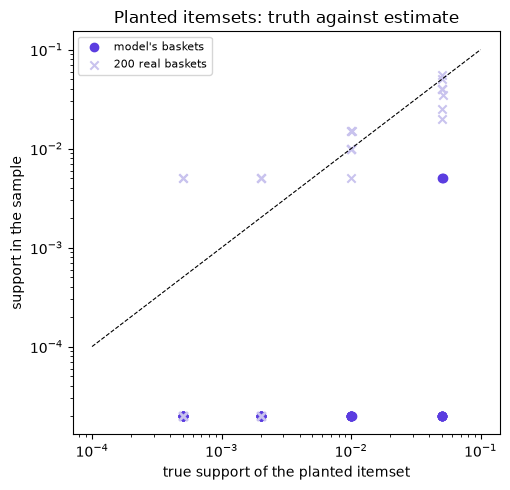

recovered 0 of 8 planted itemsets with support >= 5.0%
5% itemsets: median ratio model / truth = 0.00


In [9]:
seen = planted_table[planted_table["true support"] >= 0.0005]
fig, ax = plt.subplots(figsize=(5.2, 5))
ax.scatter(seen["true support"], seen["model's baskets"].clip(lower=2e-5), color="#5b3de0", label="model's baskets")
ax.scatter(seen["true support"], seen["real sample"].clip(lower=2e-5), color="#c9c3ee", marker="x", label=f"{N:,} real baskets")
low, high = 1e-4, 0.1
ax.plot([low, high], [low, high], "k--", lw=0.8)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("true support of the planted itemset")
ax.set_ylabel("support in the sample")
ax.legend(fontsize=8)
ax.set_title("Planted itemsets: truth against estimate")
plt.tight_layout()
plt.show()

visible = planted_table[planted_table["visible at this floor"]]
print(f"recovered {int(visible['recovered'].sum())} of {len(visible)} planted itemsets with support >= {FLOOR:.1%}")
five = planted_table[planted_table["true support"] >= 0.04]
ratio = np.median(five["model's baskets"] / five["true support"])
print(f"5% itemsets: median ratio model / truth = {ratio:.2f}")

## Single items first

the 300 most common items: correlation of the two supports 0.86, the model's support is 52% of the truth (median)
items per basket: model 5.5, real 9.5


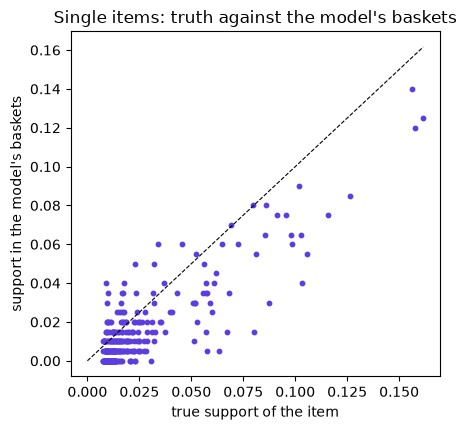

In [10]:
from collections import Counter

true_single = {next(iter(i)): s for i, s in data.truth.items() if len(i) == 1}
written = Counter(item for basket in sampled for item in basket)
top = sorted(true_single, key=true_single.get, reverse=True)[:300]
truth_s = np.array([true_single[i] for i in top])
model_s = np.array([written[i] / len(sampled) for i in top])
print(f"the 300 most common items: correlation of the two supports {np.corrcoef(truth_s, model_s)[0, 1]:.2f}, "
      f"the model's support is {np.median(model_s / truth_s):.0%} of the truth (median)")
print(f"items per basket: model {sum(written.values()) / len(sampled):.1f}, real {sum(true_single.values()):.1f}")

fig, ax = plt.subplots(figsize=(4.6, 4.4))
ax.scatter(truth_s, model_s, s=10, color="#5b3de0")
ax.plot([0, truth_s.max()], [0, truth_s.max()], "k--", lw=0.8)
ax.set_xlabel("true support of the item")
ax.set_ylabel("support in the model's baskets")
ax.set_title("Single items: truth against the model's baskets")
plt.tight_layout()
plt.show()

## What the model claims that is not true (precision)

In [11]:
claimed = {i: s for i, s in found.items()}
print(f"precision at {FLOOR:.1%}: {precision_of(claimed, data.truth, FLOOR):.0%} of the itemsets frequent in the model's baskets are truly frequent")
wrong = [i for i in claimed if data.truth.get(i, 0) < FLOOR]
print(f"{len(wrong)} are not; the real support of the worst few:")
for i in sorted(wrong, key=lambda i: -claimed[i])[:5]:
    print(f"  model {claimed[i]:.2%}, real {data.truth.get(i, 0):.2%}   {sorted(i)}")

error = support_error(found, truth)
shared = [i for i in found if i in truth]
print(f"\nfor the {len(shared):,} itemsets in both: correlation of the two supports {np.corrcoef([found[i] for i in shared], [truth[i] for i in shared])[0, 1]:.2f}, "
      f"model lower by {-error.mean():.2%} on average (supports in the model's baskets are smaller)")

precision at 5.0%: nan% of the itemsets frequent in the model's baskets are truly frequent
0 are not; the real support of the worst few:

for the 0 itemsets in both: correlation of the two supports nan, model lower by nan% on average (supports in the model's baskets are smaller)


## What the numbers say (read with the reductions in mind)

- **The test is near its limit at this size.** Even 200 *real* baskets recover only 15 of the 84 true itemsets
  (18%). The floor (5%) sits right at the true support of the planted 5% sets and their parts (5.0–6.0%), and an
  itemset expected ~10 times in 200 baskets falls just below 10 about half the time. So the ceiling is low, not the
  truth wrong.
- **The model recovers none of them (0 of 84).** In its 200 baskets it wrote two of the eight 5% planted pairs
  together once each (0.5%, against ~5% in real baskets), and never wrote the larger planted sets together.
- **Single items are learned in shape but not in size:** the 300 commonest items correlate 0.86 with the truth,
  but at about half their true support, because the model's baskets are short (5.5 items vs 9.5) and 23% of the
  names it writes are not real catalogue items (course, 800 steps: 2%).
- **Precision is undefined** (no itemset reaches 5% in the model's baskets).

So, after only 100 training steps and 200 samples, the model has learned the shop's vocabulary and popular items
roughly, but its own baskets don't yet reproduce even the most common planted patterns — while section 9 showed it
can already *complete* some of them when shown the rest. The course's longer run (800 steps, 10,000 samples) found
the same split, much less extreme: 7 of the 8 planted 5% sets recovered, at about a tenth of their true support.

## What I changed from the course (no Mac), and every reduction

- **Sampler:** `work/mybasket/probe.py`, a PyTorch port of the MLX `sample_baskets`: batches of 100 from "Basket:",
  one token per step with a shared key/value cache, temperature 1.0 from the full distribution (`torch.multinomial`
  on the softmax, so no top-k — the course's appendix warns that `generate`'s default top-k=50 would change what we
  measure), same cleaning rules, progress saved per batch.
- **Reductions (to save time):** model trained 100 steps (course 800); sampler stopped after 200 baskets (course
  10,000) because writing took ~4–5 min per 100 on CPU (`mybasket/keep_samples.py` turns the batches already written
  into the samples file, with the sampler's own cleaning rules); ceiling from 200 real baskets; support floor 5%
  (course 0.2%) so an itemset at the floor is still expected ~10 times; one support band, and the size cut at 5%.
- **Very noisy** at these sizes — read the patterns (model vs ceiling, pairs vs larger sets), not the exact numbers.

## Test yourself

**1. Why do we need a "ceiling" built from real baskets?**
A small sample misses some truly frequent itemsets by bad luck, even if it is perfect. The ceiling shows how much a
perfect model would recover at the same sample size, so a gap below it is the model's fault, not the sample's.

**2. Why was the support floor raised when the sample got smaller?**
An itemset is only "seen" if it shows up enough times in the sample. With 200 baskets, an itemset at 0.2% appears
less than once, so we can't tell found from missed. At 5% it is expected about 10 times, which we can still count.

**3. The model can complete a planted set when shown the rest (section 9), yet rarely writes the whole set itself.
Why are these different?**
Completing needs one good guess with strong hints. Writing a set from nothing needs several items chosen together
in one basket, at temperature 1.0 where each choice is only moderately sure; the chances multiply and the set breaks.

## My notes

Asking the model to write its own baskets is a much harder test than completing one: after 100 steps it recovered none of the 84 itemsets at 5%, while 200 real baskets recovered 15. Surprising: with only 200 baskets even the real-data ceiling is just 18%, so the sample size, not just the model, limits what this section can show.